### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Setup

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# One consistent look for every chart in the notebook
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
ACCEPT_COLOR, REJECT_COLOR = '#2a78d6', '#eb6834'
OUTCOME_PALETTE = {'Accepted': ACCEPT_COLOR, 'Rejected': REJECT_COLOR}

# Category orders so ordinal answers plot in a sensible sequence, with readable labels
FREQ_ORDER = ['never', 'less1', '1~3', '4~8', 'gt8']
FREQ_LABELS = {'never': 'Never', 'less1': '< 1', '1~3': '1-3', '4~8': '4-8', 'gt8': '8+'}
TIME_ORDER = ['7AM', '10AM', '2PM', '6PM', '10PM']
AGE_ORDER = ['below21', '21', '26', '31', '36', '41', '46', '50plus']
AGE_LABELS = {'below21': '< 21', '21': '21-25', '26': '26-30', '31': '31-35', '36': '36-40',
              '41': '41-45', '46': '46-49', '50plus': '50+'}
INCOME_ORDER = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999',
                '$50000 - $62499', '$62500 - $74999', '$75000 - $87499', '$87500 - $99999',
                '$100000 or More']
INCOME_LABELS = dict(zip(INCOME_ORDER, ['< 12.5k', '12.5-25k', '25-37.5k', '37.5-50k', '50-62.5k',
                                        '62.5-75k', '75-87.5k', '87.5-100k', '100k+']))

In [3]:
def compare_groups(df, mask, label):
    """Acceptance rate for drivers inside `mask` vs everyone else, with a chi-square test."""
    groups = np.where(mask, label, 'All others')
    summary = (df.groupby(groups)['Y']
                 .agg(acceptance_rate='mean', drivers='size')
                 .reindex([label, 'All others']))
    p_value = chi2_contingency(pd.crosstab(mask, df['Y']))[1]
    summary['acceptance_rate'] = summary['acceptance_rate'].round(3)
    print(f'Difference: {summary.acceptance_rate.iloc[0] - summary.acceptance_rate.iloc[1]:+.1%}'
          f'  |  chi-square p-value: {p_value:.2g}')
    return summary


def plot_rate(ax, df, column, order, title, labels=None, xlabel=None):
    """Bar chart of the acceptance rate per category, with the group's overall rate as a reference line."""
    rates = df.groupby(column)['Y'].mean().reindex(order)
    tick_labels = [labels.get(v, v) if labels else str(v) for v in order]
    ax.bar(tick_labels, rates.values, color=ACCEPT_COLOR, width=0.65)
    ax.axhline(df['Y'].mean(), color='#52514e', linestyle='--', linewidth=1,
               label=f"Overall {df['Y'].mean():.0%}")
    for x, rate in enumerate(rates.values):
        ax.text(x, rate + 0.02, f'{rate:.0%}', ha='center', fontsize=9, color='#0b0b0b')
    ax.set(title=title, ylim=(0, 1), ylabel='Acceptance rate', xlabel=xlabel or '')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.legend(loc='upper left', fontsize=8, frameon=False)
    ax.tick_params(axis='x', labelsize=9)

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [4]:
data = pd.read_csv('data/coupons.csv')

In [5]:
data = pd.read_csv('data/coupons.csv')
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [6]:
print(f'Rows: {data.shape[0]:,}  |  Columns: {data.shape[1]}  |  Exact duplicate rows: {data.duplicated().sum()}')

# Missing values, only for the columns that have any
missing = data.isna().sum()
missing = (pd.DataFrame({'missing': missing, 'percent': (missing / len(data) * 100).round(1)})
             .query('missing > 0')
             .sort_values('missing', ascending=False))
missing

Rows: 12,684  |  Columns: 26  |  Exact duplicate rows: 74


,missing,percent
car,12576,99.1
CoffeeHouse,217,1.7
Restaurant20To50,189,1.5
CarryAway,151,1.2
RestaurantLessThan20,130,1.0
Bar,107,0.8


In [7]:
# Categorical columns stored as text that need an explicit order, plus a misspelled column name
for column in ['passanger', 'age', 'Bar', 'expiration']:
    print(f'{column:<10}', sorted(data[column].dropna().unique()))

passanger  ['Alone', 'Friend(s)', 'Kid(s)', 'Partner']
age        ['21', '26', '31', '36', '41', '46', '50plus', 'below21']
Bar        ['1~3', '4~8', 'gt8', 'less1', 'never']
expiration ['1d', '2h']


There are several problems in the data, which limit what we can ascertain from it:

- The `car` column is 99% empty.
- The "how often do you visit..." columns are each missing 1% to 2% of answers.
- 74 rows are exact duplicates.
- The passenger column name is misspelled (`passanger`).

3. Decide what to do about your missing data -- drop, replace, other...

In [8]:
coupons = (data
           .drop(columns='car')            # 99% missing: drop the column
           .drop_duplicates()              # exact repeats add no information
           .dropna()                       # remaining gaps are in the visit-frequency columns (< 5% of rows)
           .rename(columns={'passanger': 'passenger'}))

# Readable outcome label for charts
coupons['outcome'] = coupons['Y'].map({1: 'Accepted', 0: 'Rejected'})

print(f'Rows kept: {len(coupons):,} of {len(data):,} ({len(coupons) / len(data):.1%})')

Rows kept: 12,007 of 12,684 (94.7%)


In order to get a better read of the data, we deleted the entire empty `car` column, the duplicates, and the rows with gaps, which still left us with 94.7% of the data. The rows we deleted were the ones missing the habit answers, which is the strongest signal, so we weren't leaving out something unimportant: filling them with a guess would have put wrong answers into the most important columns. Losing about 5% of the rows was safer than guessing.

4. What proportion of the total observations chose to accept the coupon?



In [9]:
acceptance_rate = coupons['Y'].mean()
print(f'{acceptance_rate:.1%} of all coupons offered were accepted')

56.8% of all coupons offered were accepted


5. Use a bar plot to visualize the `coupon` column.

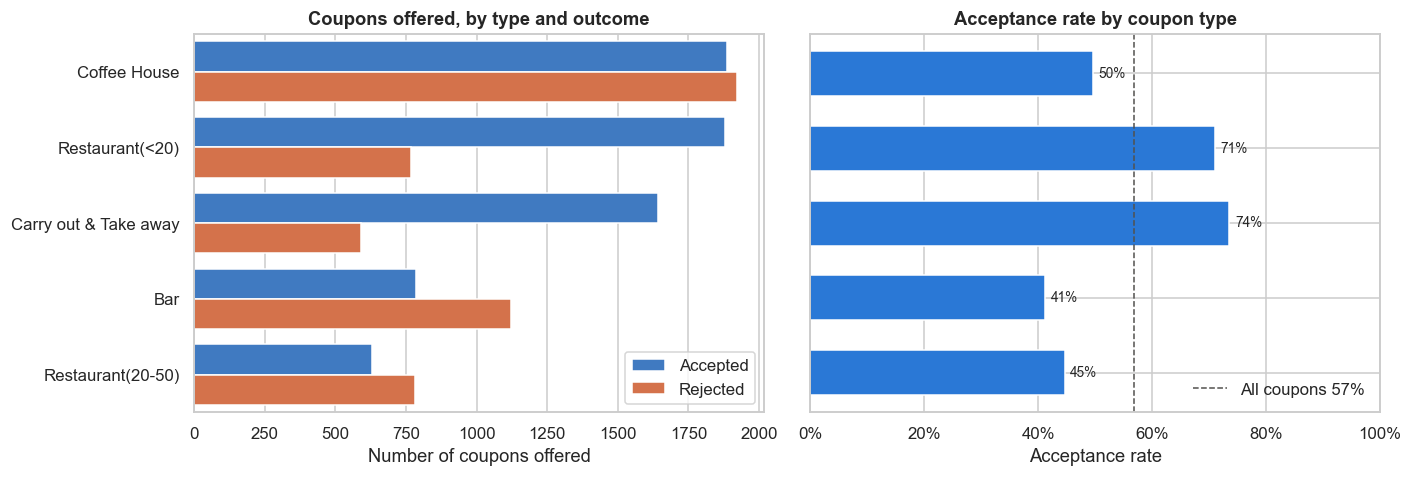

In [10]:
coupon_order = coupons['coupon'].value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: how often each coupon type was offered, split by outcome
sns.countplot(data=coupons, y='coupon', hue='outcome', order=coupon_order,
              palette=OUTCOME_PALETTE, ax=axes[0])
axes[0].set(title='Coupons offered, by type and outcome', xlabel='Number of coupons offered', ylabel='')
axes[0].legend(title='')

# Right: share accepted for each coupon type
rate_by_coupon = coupons.groupby('coupon')['Y'].mean().reindex(coupon_order)
axes[1].barh(rate_by_coupon.index, rate_by_coupon.values, color=ACCEPT_COLOR, height=0.6)
axes[1].axvline(acceptance_rate, color='#52514e', linestyle='--', linewidth=1,
                label=f'All coupons {acceptance_rate:.0%}')
for y, rate in enumerate(rate_by_coupon.values):
    axes[1].text(rate + 0.01, y, f'{rate:.0%}', va='center', fontsize=9)
axes[1].set(title='Acceptance rate by coupon type', xlabel='Acceptance rate', xlim=(0, 1), yticklabels=[])
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[1].invert_yaxis()
axes[1].legend(loc='lower right', frameon=False)

plt.tight_layout()
fig.savefig('images/coupon_types.png', bbox_inches='tight')
plt.show()

Coffee House coupons are sent out most often, and half are accepted. They serve a larger proportion of the audience than expensive restaurants or bars, which have limiting factors such as age and price and are not as habit-forming. Carry-out and cheap restaurants serve a functional need for a larger proportion of the population. It also tells us that coffee houses require more investment in coupons than carry-out and cheap restaurants, while the ticket size is small compared to expensive restaurants or even bars.

6. Use a histogram to visualize the temperature column.

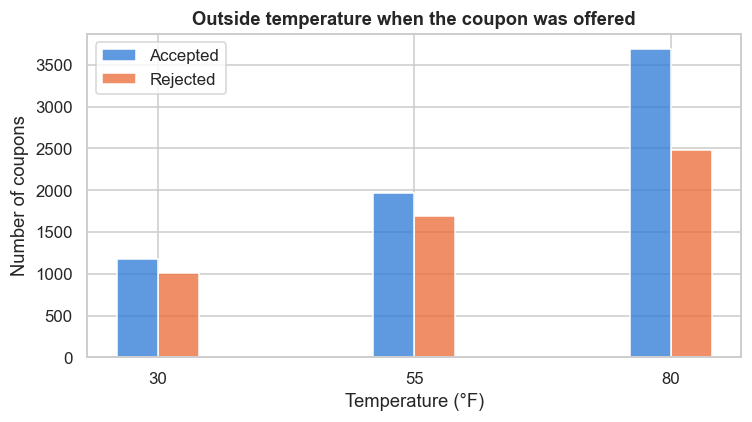

,acceptance_rate,coupons
temperature,,
30,0.538,2184
55,0.537,3652
80,0.598,6171


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=coupons, x='temperature', hue='outcome', hue_order=['Accepted', 'Rejected'],
             palette=OUTCOME_PALETTE, multiple='dodge', discrete=True, shrink=8, ax=ax)
ax.set(title='Outside temperature when the coupon was offered', xlabel='Temperature (°F)',
       ylabel='Number of coupons', xticks=[30, 55, 80])
ax.get_legend().set_title('')
plt.tight_layout()
plt.show()

coupons.groupby('temperature')['Y'].agg(acceptance_rate='mean', coupons='size').round(3)

People accept coupons more on warm days, which tells us that on warm days people are going out more. The same holds for coffee houses (53% on warm days against about 45% on colder ones): it is not only hot coffee that is served there; refreshers and other cold drinks are served too.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [12]:
bar_coupons = coupons[coupons['coupon'] == 'Bar'].copy()
print(f'{len(bar_coupons):,} bar coupons')

1,906 bar coupons


2. What proportion of bar coupons were accepted?


In [13]:
print(f"{bar_coupons['Y'].mean():.1%} of bar coupons were accepted")

41.2% of bar coupons were accepted


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [14]:
three_or_fewer = bar_coupons['Bar'].isin(['never', 'less1', '1~3'])
compare_groups(bar_coupons, ~three_or_fewer, 'Bar more than 3 times a month')

Difference: +39.0%  |  chi-square p-value: 4.7e-25


,acceptance_rate,drivers
Bar more than 3 times a month,0.762,193
All others,0.372,1713


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [15]:
# "More than once a month" = 1-3, 4-8 or 8+ visits; "over 25" excludes the under-21 and 21-25 bands
bar_more_than_once = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])
over_25 = ~bar_coupons['age'].isin(['below21', '21'])
compare_groups(bar_coupons, bar_more_than_once & over_25, 'Bar > 1/month and over 25')

Difference: +35.3%  |  chi-square p-value: 5.1e-37


,acceptance_rate,drivers
Bar > 1/month and over 25,0.690,403
All others,0.337,1503


Yes, there is a difference: bar-goers over 25 accepted 69%, against 34% for everyone else. I think those are mostly people in their working ages, and that social habit, that habit formation, happens around that age.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [16]:
no_kid_passenger = bar_coupons['passenger'] != 'Kid(s)'
not_farming = bar_coupons['occupation'] != 'Farming Fishing & Forestry'
compare_groups(bar_coupons, bar_more_than_once & no_kid_passenger & not_farming,
               'Bar > 1/month, no kids, not farming')

Difference: +41.2%  |  chi-square p-value: 6e-60


,acceptance_rate,drivers
"Bar > 1/month, no kids, not farming",0.709,530
All others,0.297,1376


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [17]:
not_widowed = bar_coupons['maritalStatus'] != 'Widowed'
under_30 = bar_coupons['age'].isin(['below21', '21', '26'])
cheap_restaurant_4_plus = bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8'])
income_under_50k = bar_coupons['income'].isin(INCOME_ORDER[:4])

bar_conditions = {
    'Bar > 1/month, no kids, not widowed': bar_more_than_once & no_kid_passenger & not_widowed,
    'Bar > 1/month, under 30': bar_more_than_once & under_30,
    'Cheap restaurants 4+/month, income < 50K': cheap_restaurant_4_plus & income_under_50k,
}
bar_conditions['Any of the three'] = np.logical_or.reduce(list(bar_conditions.values()))

for label, mask in bar_conditions.items():
    print(label)
    display(compare_groups(bar_coupons, mask, label))

Bar > 1/month, no kids, not widowed
Difference: +41.2%  |  chi-square p-value: 6e-60


,acceptance_rate,drivers
"Bar > 1/month, no kids, not widowed",0.709,530
All others,0.297,1376


Bar > 1/month, under 30
Difference: +37.2%  |  chi-square p-value: 3.3e-35


,acceptance_rate,drivers
"Bar > 1/month, under 30",0.720,328
All others,0.348,1578


Cheap restaurants 4+/month, income < 50K
Difference: +5.4%  |  chi-square p-value: 0.079


,acceptance_rate,drivers
"Cheap restaurants 4+/month, income < 50K",0.456,333
All others,0.402,1573


Any of the three
Difference: +28.8%  |  chi-square p-value: 2e-35


,acceptance_rate,drivers
Any of the three,0.587,746
All others,0.299,1160


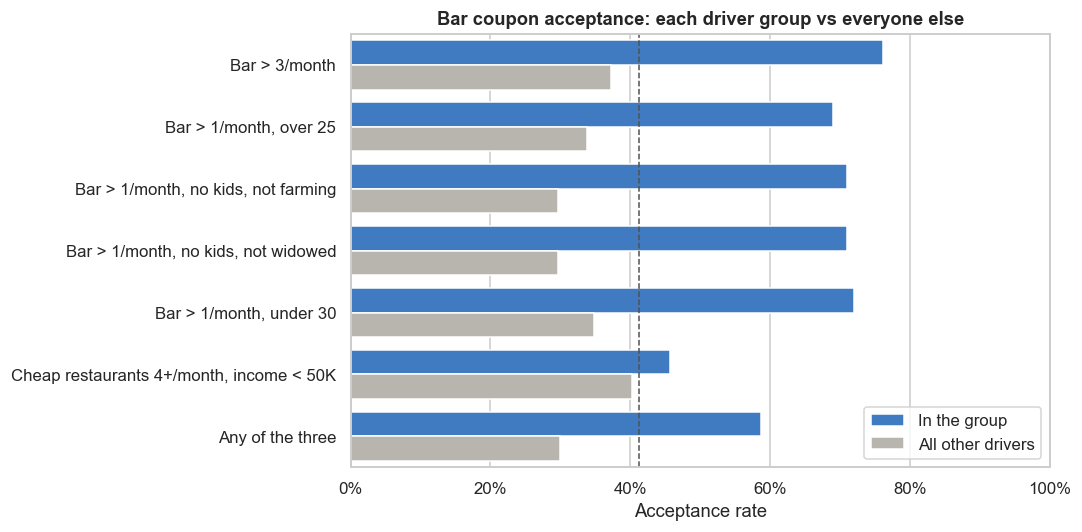

In [18]:
# One chart comparing every group above with the drivers outside it
bar_segments = {'Bar > 3/month': ~three_or_fewer,
                'Bar > 1/month, over 25': bar_more_than_once & over_25,
                'Bar > 1/month, no kids, not farming': bar_more_than_once & no_kid_passenger & not_farming,
                **bar_conditions}
segment_rates = pd.DataFrame(
    [{'segment': label, 'In the group': bar_coupons.loc[mask, 'Y'].mean(),
      'All other drivers': bar_coupons.loc[~mask, 'Y'].mean()} for label, mask in bar_segments.items()]
).melt(id_vars='segment', var_name='who', value_name='rate')

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=segment_rates, y='segment', x='rate', hue='who',
            palette=[ACCEPT_COLOR, '#b8b6ad'], ax=ax)
ax.axvline(bar_coupons['Y'].mean(), color='#52514e', linestyle='--', linewidth=1)
ax.set(title='Bar coupon acceptance: each driver group vs everyone else', xlabel='Acceptance rate',
       ylabel='', xlim=(0, 1))
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(title='', loc='lower right')
plt.tight_layout()
fig.savefig('images/bar_segments.png', bbox_inches='tight')
plt.show()

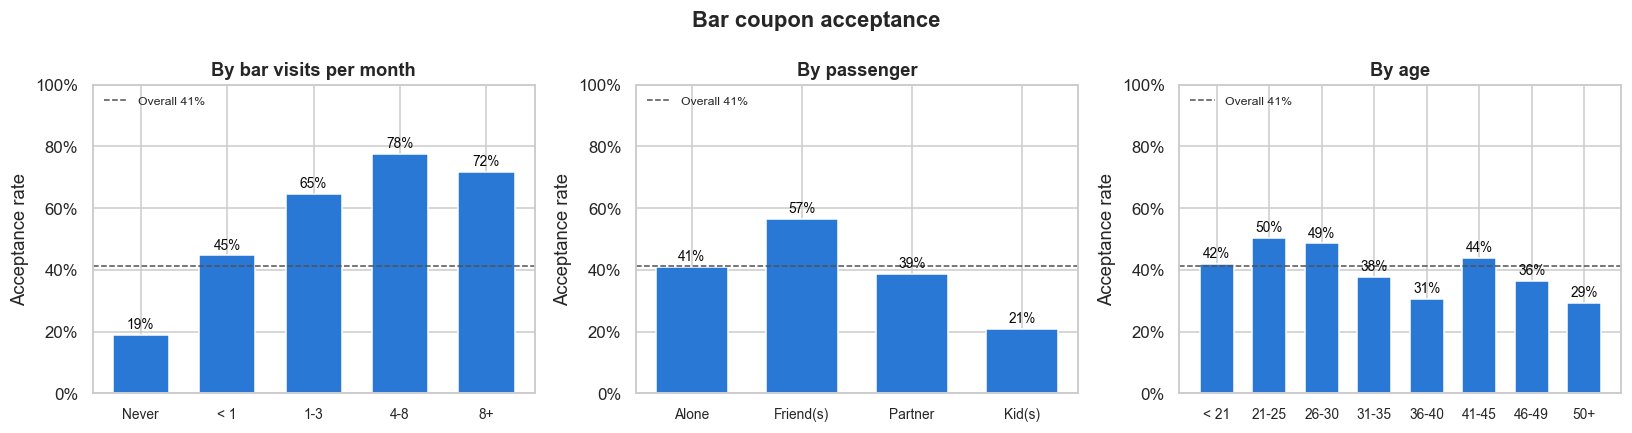

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_rate(axes[0], bar_coupons, 'Bar', FREQ_ORDER, 'By bar visits per month', FREQ_LABELS)
plot_rate(axes[1], bar_coupons, 'passenger', ['Alone', 'Friend(s)', 'Partner', 'Kid(s)'], 'By passenger')
plot_rate(axes[2], bar_coupons, 'age', AGE_ORDER, 'By age', AGE_LABELS)
fig.suptitle('Bar coupon acceptance', fontweight='bold')
plt.tight_layout()
plt.show()

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

**Hypothesis**

Drivers who already go to bars more than once a month are the most likely to accept a bar coupon. If they don't already go regularly, success depends on other factors, like their age and whether they have kids in the car.

Having friends in the car helps. I think this is because a bar is a social setting most often, and people go in groups; a bar is engineered towards social and bonding activities over alcohol.

Having kids in the car is a deterrent, because kids are not allowed in bars; you need to be above the drinking age, which is well into adulthood in most cases.

Younger drivers, 21 to 30, are more likely to accept, since going to bars is a social activity that mostly young people engage in. But among people who already go to bars regularly, age makes little difference.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

#### Problem: who accepts a Coffee House coupon?

I decided to go with the Coffee House coupon because it was the coupon sent out most often, and the chance of somebody accepting it was 50/50. It was a harder category to get responses for than carry-out and cheap restaurant coupons, which already seem to get a lot of success, so it is more interesting to see why people accept or don't. From a business point of view, bars and expensive restaurants are sent out much less often, so changing them would affect fewer coupons. Coffee is the place where changing certain things would make a meaningful difference.

In [20]:
coffee_coupons = coupons[coupons['coupon'] == 'Coffee House'].copy()

# Combine the three distance flags into one readable column
coffee_coupons['distance'] = np.select(
    [coffee_coupons['toCoupon_GEQ25min'] == 1, coffee_coupons['toCoupon_GEQ15min'] == 1],
    ['25+ min', '15-25 min'], default='< 15 min')

print(f"{len(coffee_coupons):,} Coffee House coupons, {coffee_coupons['Y'].mean():.1%} accepted")

3,809 Coffee House coupons, 49.6% accepted


##### Trip conditions and coffee habit

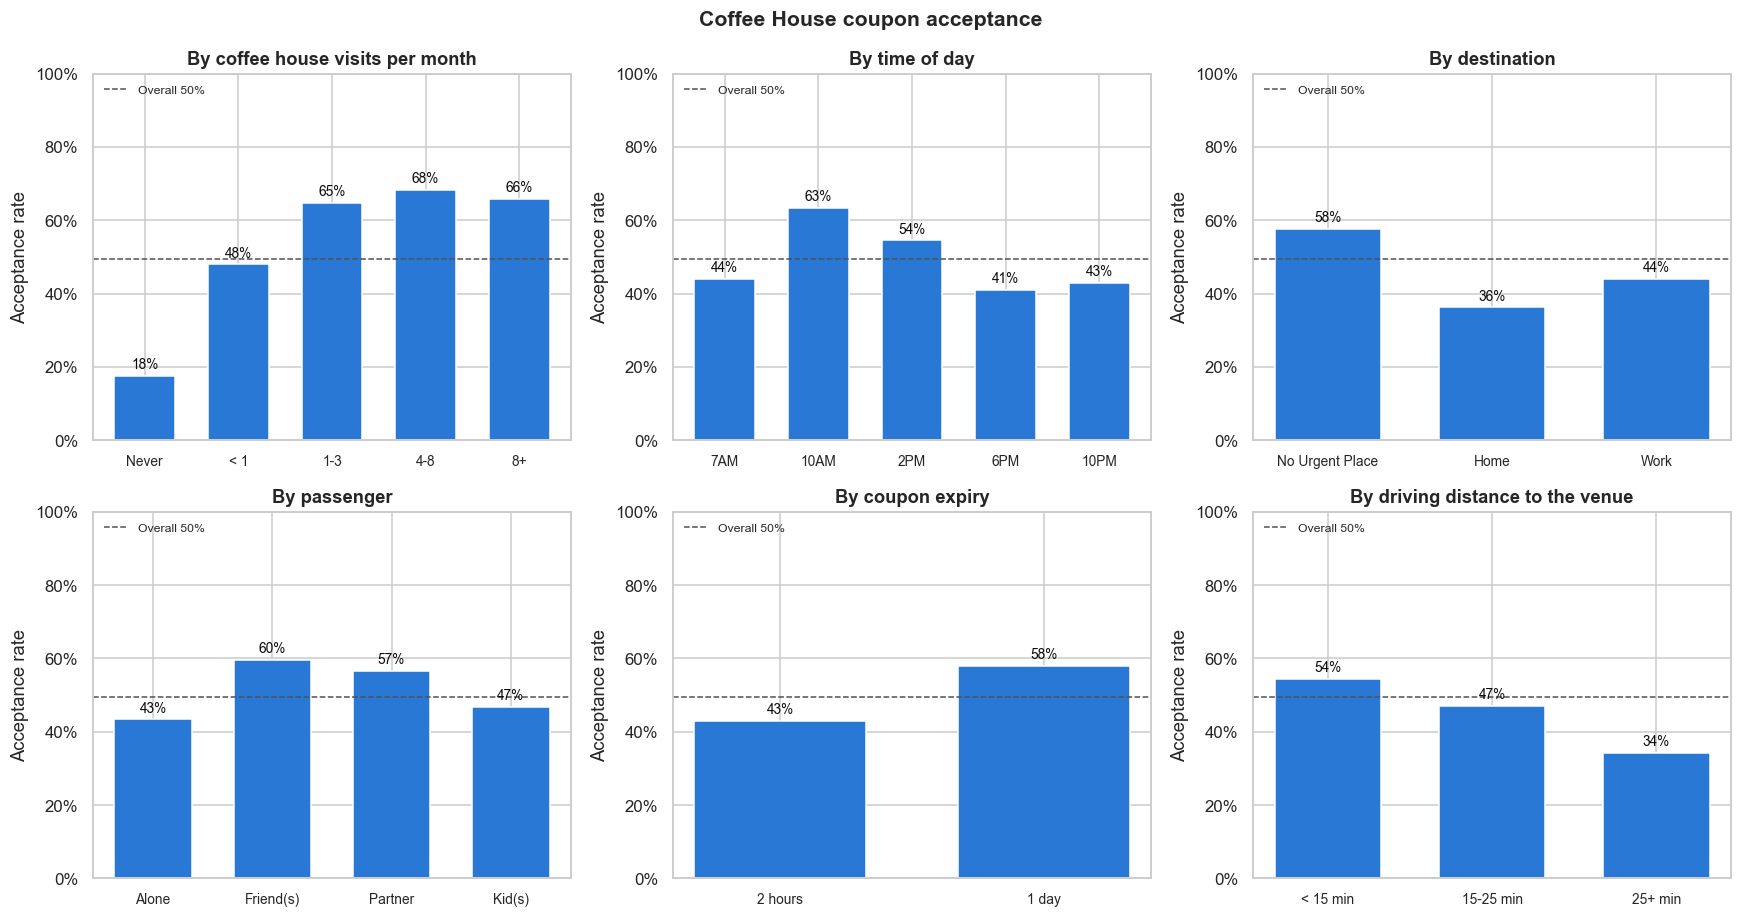

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
plot_rate(axes[0, 0], coffee_coupons, 'CoffeeHouse', FREQ_ORDER, 'By coffee house visits per month', FREQ_LABELS)
plot_rate(axes[0, 1], coffee_coupons, 'time', TIME_ORDER, 'By time of day')
plot_rate(axes[0, 2], coffee_coupons, 'destination', ['No Urgent Place', 'Home', 'Work'], 'By destination')
plot_rate(axes[1, 0], coffee_coupons, 'passenger', ['Alone', 'Friend(s)', 'Partner', 'Kid(s)'], 'By passenger')
plot_rate(axes[1, 1], coffee_coupons, 'expiration', ['2h', '1d'], 'By coupon expiry',
          {'2h': '2 hours', '1d': '1 day'})
plot_rate(axes[1, 2], coffee_coupons, 'distance', ['< 15 min', '15-25 min', '25+ min'], 'By driving distance to the venue')
fig.suptitle('Coffee House coupon acceptance', fontweight='bold', fontsize=14)
plt.tight_layout()
fig.savefig('images/coffee_drivers.png', bbox_inches='tight')
plt.show()

About half the drivers go to a coffee house at least once a month, and they are the ones who accept: for them, going to a coffee house is somewhat of a ritual. People who never go almost never accept.

Time of day matters. Coupons do best when they reach people when they usually go: mid-morning, when people usually have a dip in their energy and go for coffee to get that jolt during the workday, and the afternoon. Mostly it is during daylight hours that people go for coffee to power through the day.

When people are going nowhere urgent, a lot of times they stop by for coffee; it's not only for work-related energy. Compared to the other things, coffee is not much of a time commitment or a cost deterrent.

People with a friend or a partner in the car accept more often, since coffee has always been a social activity, with people sitting in coffee houses to meet over a cup of coffee. Drivers alone or with kids accept less.

Less urgency is good: a one-day coupon does better than a two-hour one. Since coffee is something people are going to get anyway, they don't really feel a sense of urgency about it.

People prefer not to go too far out of the way for a cup of coffee, because it doesn't have as much product differentiation as a meal or a cuisine; coffee houses usually have very similar and limited menus.

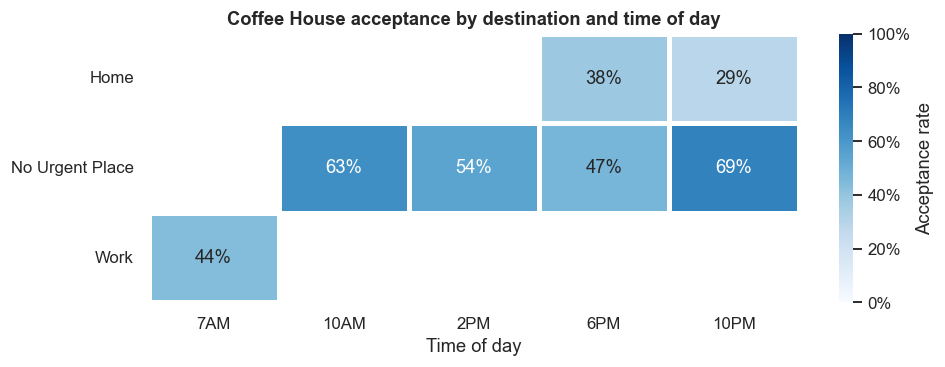

In [22]:
# Time of day and destination together: which moments work best?
time_destination = coffee_coupons.pivot_table(index='destination', columns='time', values='Y',
                                              aggfunc='mean').reindex(columns=TIME_ORDER)

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(time_destination, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1,
            linewidths=2, linecolor='white', cbar_kws={'label': 'Acceptance rate', 'format': plt.matplotlib.ticker.PercentFormatter(1.0)}, ax=ax)
ax.grid(False)
ax.tick_params(axis='y', rotation=0)
ax.set(title='Coffee House acceptance by destination and time of day', xlabel='Time of day', ylabel='')
plt.tight_layout()
plt.show()

When people are going home in the evening, they are not that likely to take a coffee coupon, simply because coffee is a stimulant used for more energy and has no functional use in the evening: on the drive home you would most likely be winding down for the day, and it is also part of the commute. Acceptance hits a high point mid-morning and starts falling from midday. Late at night, on trips with no urgent destination, people might have coffee for a different purpose: as a social setting, more of a social lubricant, similar to a bar, instead of functional coffee drinking (only 99 drivers are in that group, though).

##### Who the drivers are

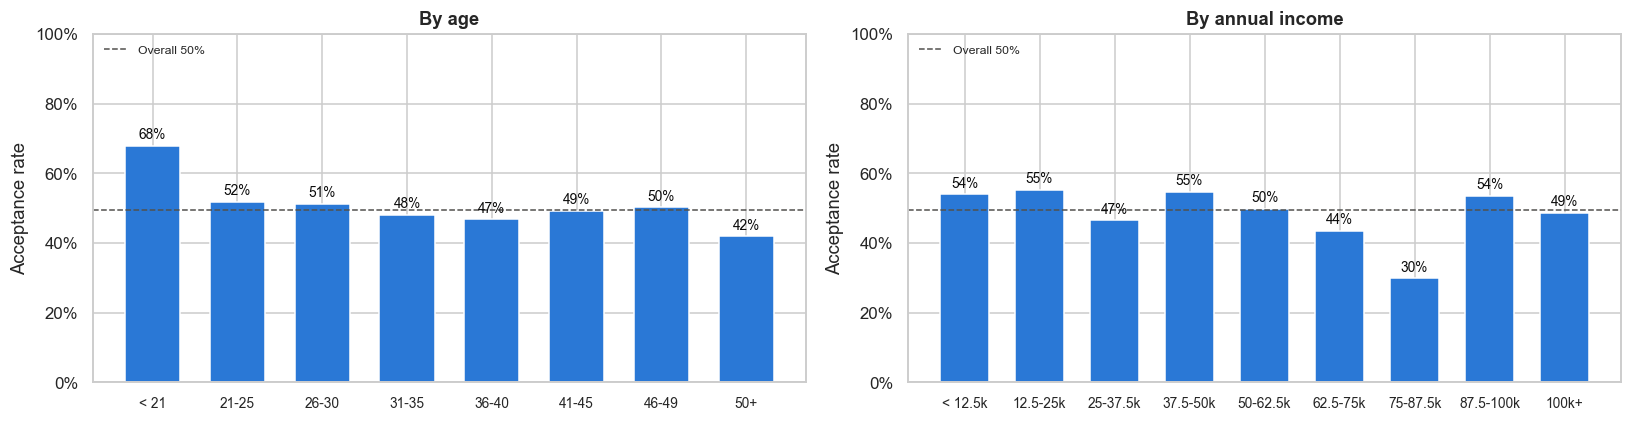

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_rate(axes[0], coffee_coupons, 'age', AGE_ORDER, 'By age', AGE_LABELS)
plot_rate(axes[1], coffee_coupons, 'income', INCOME_ORDER, 'By annual income', INCOME_LABELS)
plt.tight_layout()
plt.show()

Coffee is not really age-based; a lot of people drink coffee generally. Drivers under 21 accept more often, possibly because coffee houses are places where they can get together since they can't go to bars yet. That group is small (143 people), so I wouldn't be very confident in it. Income doesn't show much of an effect either: coffee is relatively affordable and doesn't require a certain level of sophistication; it's an everyman's drink. It is more the habit of drinking coffee, for its energy and its social side, that decides acceptance than age or income.

##### Which differences are real? Chi-square tests and effect sizes

In [24]:
def cramers_v(table):
    """Strength of association between two categorical variables (0 = none, 1 = perfect)."""
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))


candidate_features = ['CoffeeHouse', 'destination', 'time', 'passenger', 'expiration', 'distance',
                      'age', 'income', 'occupation', 'temperature', 'weather', 'education',
                      'maritalStatus', 'has_children', 'gender']
tests = []
for feature in candidate_features:
    table = pd.crosstab(coffee_coupons[feature], coffee_coupons['Y'])
    tests.append({'feature': feature, 'p_value': chi2_contingency(table)[1], 'cramers_v': cramers_v(table)})

tests = pd.DataFrame(tests).sort_values('cramers_v', ascending=False).set_index('feature')
tests['significant (p < 0.05)'] = tests['p_value'] < 0.05
tests.style.format({'p_value': '{:.1e}', 'cramers_v': '{:.2f}'})

,p_value,cramers_v,significant (p < 0.05)
feature,,,
CoffeeHouse,7.0e-122,0.39,True
destination,1.4e-28,0.18,True
time,7.8e-25,0.18,True
occupation,3.8e-12,0.17,True
passenger,8.1e-19,0.15,True
expiration,3.0e-20,0.15,True
income,7.1e-10,0.12,True
distance,1.6e-11,0.11,True
age,8.6e-06,0.10,True


The coffee habit turns out to be the biggest determinant (0.39). Caffeine is an addictive stimulant, and people who have the habit almost become dependent on it to get through the day. Destination, time, occupation, passenger and expiry also matter quite a bit: people going home don't need coffee, and coffee keeps you awake, so the time of day counts. Income, distance, age and temperature have a much weaker effect, and there is very little evidence that weather, education, marital status, having children or gender matter at all. Occupation could matter, for example desk jobs versus physical labour, but I would have to see whether that is a blue-collar or white-collar split.

##### Putting it together: a target segment

In [25]:
coffee_regular = coffee_coupons['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
relaxed_daytime_trip = ((coffee_coupons['destination'] == 'No Urgent Place')
                        & coffee_coupons['time'].isin(['10AM', '2PM']))

segments = {
    'Regulars on a relaxed daytime trip': coffee_regular & relaxed_daytime_trip,
    'Regulars, any trip': coffee_regular,
    'Never visit a coffee house': coffee_coupons['CoffeeHouse'] == 'never',
}
for label, mask in segments.items():
    print(label)
    display(compare_groups(coffee_coupons, mask, label))

Regulars on a relaxed daytime trip
Difference: +34.8%  |  chi-square p-value: 4.3e-67


,acceptance_rate,drivers
Regulars on a relaxed daytime trip,0.772,784
All others,0.424,3025


Regulars, any trip
Difference: +32.0%  |  chi-square p-value: 3.2e-86


,acceptance_rate,drivers
"Regulars, any trip",0.659,1864
All others,0.339,1945


Never visit a coffee house
Difference: -41.9%  |  chi-square p-value: 2.6e-106


,acceptance_rate,drivers
Never visit a coffee house,0.175,896
All others,0.594,2913


In [26]:
# 95% confidence interval for the target segment's acceptance rate (normal approximation)
target = coffee_coupons.loc[segments['Regulars on a relaxed daytime trip'], 'Y']
rate, n = target.mean(), len(target)
margin = 1.96 * np.sqrt(rate * (1 - rate) / n)
print(f'Target segment: {rate:.1%} accepted (95% CI {rate - margin:.1%} to {rate + margin:.1%}, n = {n})')

Target segment: 77.2% accepted (95% CI 74.2% to 80.1%, n = 784)


The strongest customer, in my opinion, is a coffee regular on a relaxed daytime trip: someone who goes to a coffee house at least monthly, is going nowhere urgent, and gets the coupon at 10am or 2pm. They accept 77% of the time, against 42% for everyone else. That is the ideal customer as a triangulation of all the factors.

## Findings

**Problem.** The Coffee House coupon is sent out most often but only accepted 50/50. I looked at what separates the drivers who accept it from those who don't.

- **Habit is the biggest determinant.** Drivers who go to a coffee house at least once a month accept about 66% of the time; for them it is somewhat of a ritual. People who never go accept 18%.
- **The moment matters.** Acceptance hits a high point mid-morning, when people have a dip in energy, and falls from midday. People going nowhere urgent stop by; people driving home in the evening, winding down, don't need a stimulant.
- **Company helps.** Coffee is a social activity: drivers with a friend or partner accept more than drivers alone.
- **Less urgency and short detours help.** A one-day coupon beats a two-hour one, since people get coffee anyway; and people won't go far out of their way for coffee, which has little product differentiation.
- **Who the person is matters little.** Age, income, education, marital status, children and gender barely change acceptance; coffee is an everyman's drink.
- **The ideal customer** is a coffee regular on a relaxed daytime trip: 77% accept, against 42% for everyone else.
- **Bars tell the same story.** Drivers who already go to bars are the most likely to accept a bar coupon; friends in the car help and kids in the car are a deterrent.

### Actionable items

- Send coffee coupons mainly to drivers who already go to coffee houses.
- Send them mid-morning and early afternoon, on trips with no urgent destination, not on the evening drive home.
- Give a one-day expiry rather than two hours.
- Offer cafés close to the driver's route, not 25+ minutes away.
- Send bar coupons to regular bar-goers with friends in the car, never with kids.

### Next steps and recommendations

- Run a pilot on a respectable cohort size to test these rules in practice.
- The coupons arrive on the phone, which can work very well; we could also try different platforms, such as the car radio.
- Build a way to predict, before a coupon is sent, how likely it is to be a yes.
- Check whether blue-collar or white-collar work makes a difference.